## Dataset Split

In [2]:
from pathlib import Path
import sys


def _find_helper_project_dir(start=Path.cwd()):
    start = Path(start).resolve()
    search_roots = [start, *start.parents]
    for root in search_roots:
        if (root / "helper_function" / "__init__.py").exists():
            return root
    for root in search_roots[:3]:
        matches = list(root.glob("**/boi_shift_fft3_cfpattern_spl/helper_function/__init__.py"))
        if matches:
            return matches[0].parent.parent
    raise FileNotFoundError("Could not find helper_function from the current Jupyter working directory.")


PROJECT_DIR = _find_helper_project_dir()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import math
import pandas as pd

# ============================================================
# Configurations
# ============================================================
N = 32768          # input length
Np = 64            # number of SSCA strips, N'
P = 7              # number of lag-product vectors

K1 = 33            # K for CC-trained CAP
K2 = 20            # K for LR + CAP with truth/blind Rs/CFO

logN = math.log2(N)
logNp = math.log2(Np)

# ============================================================
# Complexity functions
# ============================================================
def cc_trained_cap_feature(N, Np):
    """
    Feature extraction complexity of Snoap 2023.06 CC-trained CAP:
    NN'(log2(N') + log2(N) + 4) + 3N + Nlog2(N)
    """
    return N * Np * (math.log2(Np) + math.log2(N) + 4) + 3 * N + N * math.log2(N)

def cc_estimate(N, P, K):
    """
    CC estimation complexity:
    PN + KNlog2(N)
    """
    return P * N + K * N * math.log2(N)

def iq_boi_usp_feature(N):
    """
    I/Q-BOI-USP feature extraction:
    8N + 4Nlog2(N)
    """
    return 8 * N + 4 * N * math.log2(N)

def lr_only_feature(N):
    """
    Proposed LR-only feature extraction:
    8N + 3Nlog2(N) + 275
    """
    return 8 * N + 3 * N * math.log2(N) + 275

# ============================================================
# Calculate Total MAC
# ============================================================
models = []

# 1. CC-trained CAP, use K1 = 33
feature = cc_trained_cap_feature(N, Np)
cc = cc_estimate(N, P, K1)
total = feature + cc
models.append({
    "Model": "CC-trained CAP",
    "K Used": K1,
    "Feature Extraction": feature,
    "CC Estimate": cc,
    "Total MAC": total,
})

# 2. I/Q-BOI-USP, no CC estimate
feature = iq_boi_usp_feature(N)
cc = 0
total = feature + cc
models.append({
    "Model": "I/Q-BOI-USP",
    "K Used": "-",
    "Feature Extraction": feature,
    "CC Estimate": cc,
    "Total MAC": total,
})

# 3. LR-only, no CC estimate
feature = lr_only_feature(N)
cc = 0
total = feature + cc
models.append({
    "Model": "LR-only",
    "K Used": "-",
    "Feature Extraction": feature,
    "CC Estimate": cc,
    "Total MAC": total,
})

# 4. LR + CAP with truth Rs/CFO, use K2 = 20
feature = lr_only_feature(N)
cc = cc_estimate(N, P, K2)
total = feature + cc
models.append({
    "Model": "LR + CAP with truth Rs/CFO",
    "K Used": K2,
    "Feature Extraction": feature,
    "CC Estimate": cc,
    "Total MAC": total,
})

# 5. LR + CAP with blind Rs/CFO, use K2 = 20
feature = lr_only_feature(N)
cc = cc_estimate(N, P, K2)
total = feature + cc
models.append({
    "Model": "LR + CAP with blind Rs/CFO",
    "K Used": K2,
    "Feature Extraction": feature,
    "CC Estimate": cc,
    "Total MAC": total,
})

df = pd.DataFrame(models)

# Speedup relative to CC-trained CAP
baseline_total = df.loc[df["Model"] == "CC-trained CAP", "Total MAC"].iloc[0]
df["Speedup"] = baseline_total / df["Total MAC"]

# Format for display
df_display = df.copy()
for col in ["Feature Extraction", "CC Estimate", "Total MAC"]:
    df_display[col] = df_display[col].map(lambda x: f"{x:,.0f}")
df_display["Speedup"] = df_display["Speedup"].map(lambda x: f"{x:.2f}×")

print(f"N = {N}, N' = {Np}, P = {P}, K1 = {K1}, K2 = {K2}")
print(df_display.to_string(index=False))

N = 32768, N' = 64, P = 7, K1 = 33, K2 = 20
                     Model K Used Feature Extraction CC Estimate  Total MAC Speedup
            CC-trained CAP     33         53,018,624  16,449,536 69,468,160   1.00×
               I/Q-BOI-USP      -          2,228,224           0  2,228,224  31.18×
                   LR-only      -          1,736,979           0  1,736,979  39.99×
LR + CAP with truth Rs/CFO     20          1,736,979  10,059,776 11,796,755   5.89×
LR + CAP with blind Rs/CFO     20          1,736,979  10,059,776 11,796,755   5.89×


## LR-only direct 8-class classification

Use the original 55-dimensional `lr55` features to classify all eight signal types directly. No CC matrix or CAPNet stage is used. For each training year, batches 1–20 are used for training, batches 25–28 of the same year are used for same-domain testing, and all 28 batches of the other year are used for external testing. As in the pipeline notebooks, 2018 samples with negative SNR are excluded.

In [1]:
from pathlib import Path
import gc
import time

import numpy as np
import pandas as pd
import torch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Keep these settings aligned with the original LR55 pipeline.
LR8_SEED = 20260611
LR8_VECTOR_KEY = "lr55"
LR8_TRAIN_BATCH_COUNT = 20
LR8_VAL_BATCH_COUNT = 4
LR8_TEST_BATCH_COUNT = 4
LR8_DROP_2018_NEGATIVE_SNR = True
LR8_CLASS_ORDER = [
    "BPSK", "MSK", "DQPSK", "8PSK",
    "QPSK", "16QAM", "64QAM", "256QAM",
]
LR8_LABEL_MAP = {
    "bpsk": "BPSK",
    "msk": "MSK",
    "dqpsk": "DQPSK",
    "8psk": "8PSK",
    "qpsk": "QPSK",
    "16qam": "16QAM",
    "64qam": "64QAM",
    "256qam": "256QAM",
}

# The notebook is expected to run from boi_shift_fft3_cfpattern_finalresult.
LR8_DATA_ROOT = PROJECT_DIR
if not (LR8_DATA_ROOT / "2018").is_dir() or not (LR8_DATA_ROOT / "2022").is_dir():
    raise FileNotFoundError(
        "Run this notebook with the working directory set to "
        "boi_shift_fft3_cfpattern_finalresult (the folder containing 2018/ and 2022/)."
    )


def load_lr8_dataset(data_root=LR8_DATA_ROOT):
    """Load only the compact 55-D LR vectors and metadata for both years."""
    metadata_parts = []
    vector_parts = []
    feature_names = None
    start_time = time.time()

    for year in ("2018", "2022"):
        files = sorted(
            (data_root / year).glob(
                f"{year}_batch_*_boi_shift_fft3_compact_vectors.pt"
            )
        )
        if len(files) != 28:
            raise FileNotFoundError(
                f"Expected 28 compact-vector files for {year}, found {len(files)}"
            )

        for file_number, path in enumerate(files, start=1):
            pack = torch.load(path, map_location="cpu", weights_only=False)
            current_feature_names = list(
                pack["vector_feature_names"][LR8_VECTOR_KEY]
            )
            if feature_names is None:
                feature_names = current_feature_names
            elif feature_names != current_feature_names:
                raise ValueError(f"lr55 feature-name mismatch in {path}")

            rows = []
            vectors = []
            for sample in pack["samples"]:
                meta = sample["meta"]
                truth = sample["truth"]
                signal_type = str(meta["signal_type"]).strip().lower()
                if signal_type not in LR8_LABEL_MAP:
                    raise ValueError(f"Unsupported signal_type={signal_type!r}")

                rows.append({
                    "year": year,
                    "batch_id": int(meta.get("batch_id", pack.get("batch_id", -1))),
                    "label8": LR8_LABEL_MAP[signal_type],
                    "snr": float(
                        truth.get(
                            "inband_snr_db_label",
                            truth.get("snr_truth_db", np.nan),
                        )
                    ),
                })
                vectors.append(
                    np.asarray(
                        sample["vectors"][LR8_VECTOR_KEY], dtype=np.float32
                    )
                )

            metadata_parts.append(pd.DataFrame(rows))
            vector_parts.append(np.vstack(vectors).astype(np.float32, copy=False))
            print(
                f"Loaded {year} {file_number:02d}/{len(files):02d}: "
                f"{len(rows)} rows, elapsed {time.time() - start_time:.1f}s",
                flush=True,
            )
            del pack, rows, vectors
            gc.collect()

    metadata = pd.concat(metadata_parts, ignore_index=True)
    X = np.vstack(vector_parts).astype(np.float32, copy=False)

    if LR8_DROP_2018_NEGATIVE_SNR:
        keep = ~((metadata["year"] == "2018") & (metadata["snr"] < 0))
        print(f"Dropped 2018 negative-SNR rows: {int((~keep).sum())}")
        metadata = metadata.loc[keep].reset_index(drop=True)
        X = X[keep.to_numpy()]

    # Let SimpleImputer handle non-finite feature values.
    X = np.where(np.isfinite(X), X, np.nan)
    print(f"Final LR8 dataset: X={X.shape}, labels={len(metadata)}")
    return metadata, X, feature_names


def make_lr8_model():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            n_jobs=-1,
            class_weight="balanced",
            C=3,
            random_state=LR8_SEED,
        ),
    )


lr8_metadata, X_lr8, lr8_feature_names = load_lr8_dataset()
y_lr8 = lr8_metadata["label8"].astype(str).to_numpy()
lr8_result_rows = []
lr8_models = {}

for train_mode in ("2018train20", "2022train20"):
    train_year = train_mode[:4]
    external_year = "2022" if train_year == "2018" else "2018"

    train_mask = (
        (lr8_metadata["year"] == train_year)
        & (lr8_metadata["batch_id"] <= LR8_TRAIN_BATCH_COUNT)
    ).to_numpy()
    same_domain_test_mask = (
        (lr8_metadata["year"] == train_year)
        & (lr8_metadata["batch_id"] > LR8_TRAIN_BATCH_COUNT + LR8_VAL_BATCH_COUNT)
        & (
            lr8_metadata["batch_id"]
            <= LR8_TRAIN_BATCH_COUNT + LR8_VAL_BATCH_COUNT + LR8_TEST_BATCH_COUNT
        )
    ).to_numpy()
    external_test_mask = (lr8_metadata["year"] == external_year).to_numpy()

    model = make_lr8_model()
    print(f"\nTraining direct LR8 model: {train_mode}, n={train_mask.sum()}")
    train_start = time.time()
    model.fit(X_lr8[train_mask], y_lr8[train_mask])
    print(f"Training completed in {time.time() - train_start:.1f}s")
    lr8_models[train_mode] = model

    evaluations = [
        (train_year, "same-domain batches 25-28", same_domain_test_mask),
        (external_year, "external all 28 batches", external_test_mask),
    ]
    for test_year, test_scope, test_mask in evaluations:
        prediction = model.predict(X_lr8[test_mask])
        accuracy = accuracy_score(y_lr8[test_mask], prediction)
        lr8_result_rows.append({
            "Train mode": train_mode,
            "Test year": test_year,
            "Test scope": test_scope,
            "N": int(test_mask.sum()),
            "Errors": int((prediction != y_lr8[test_mask]).sum()),
            "Accuracy": accuracy,
            "Accuracy (%)": accuracy * 100.0,
        })

lr8_results = pd.DataFrame(lr8_result_rows)
print("\nDirect LR 8-class results:")
display(
    lr8_results.style.format({"Accuracy": "{:.6f}", "Accuracy (%)": "{:.4f}%"})
)

lr8_accuracy_table = lr8_results.pivot(
    index="Train mode", columns="Test year", values="Accuracy (%)"
).reindex(index=["2018train20", "2022train20"], columns=["2018", "2022"])
print("Accuracy (%) summary:")
display(lr8_accuracy_table.style.format("{:.4f}%"))

Loaded 2018 01/28: 3992 rows, elapsed 11.0s
Loaded 2018 02/28: 3984 rows, elapsed 21.5s
Loaded 2018 03/28: 3984 rows, elapsed 31.7s
Loaded 2018 04/28: 3984 rows, elapsed 41.9s
Loaded 2018 05/28: 3992 rows, elapsed 51.9s
Loaded 2018 06/28: 3984 rows, elapsed 61.9s
Loaded 2018 07/28: 3984 rows, elapsed 71.7s
Loaded 2018 08/28: 3984 rows, elapsed 81.4s
Loaded 2018 09/28: 3992 rows, elapsed 91.9s
Loaded 2018 10/28: 3984 rows, elapsed 102.9s
Loaded 2018 11/28: 3984 rows, elapsed 113.3s
Loaded 2018 12/28: 3984 rows, elapsed 123.2s
Loaded 2018 13/28: 3992 rows, elapsed 133.1s
Loaded 2018 14/28: 3984 rows, elapsed 143.1s
Loaded 2018 15/28: 3984 rows, elapsed 153.1s
Loaded 2018 16/28: 3984 rows, elapsed 163.1s
Loaded 2018 17/28: 3992 rows, elapsed 173.2s
Loaded 2018 18/28: 3984 rows, elapsed 183.3s
Loaded 2018 19/28: 3984 rows, elapsed 193.3s
Loaded 2018 20/28: 3984 rows, elapsed 203.8s
Loaded 2018 21/28: 3992 rows, elapsed 214.0s
Loaded 2018 22/28: 3992 rows, elapsed 224.2s
Loaded 2018 23/28: 

,Train mode,Test year,Test scope,N,Errors,Accuracy,Accuracy (%)
0,2018train20,2018,same-domain batches 25-28,15960,2566,0.839223,83.9223%
1,2018train20,2022,external all 28 batches,112000,25102,0.775875,77.5875%
2,2022train20,2022,same-domain batches 25-28,16000,2696,0.831500,83.1500%
3,2022train20,2018,external all 28 batches,111632,20819,0.813503,81.3503%


Accuracy (%) summary:


Test year,2018,2022
Train mode,,
2018train20,83.9223%,77.5875%
2022train20,81.3503%,83.1500%


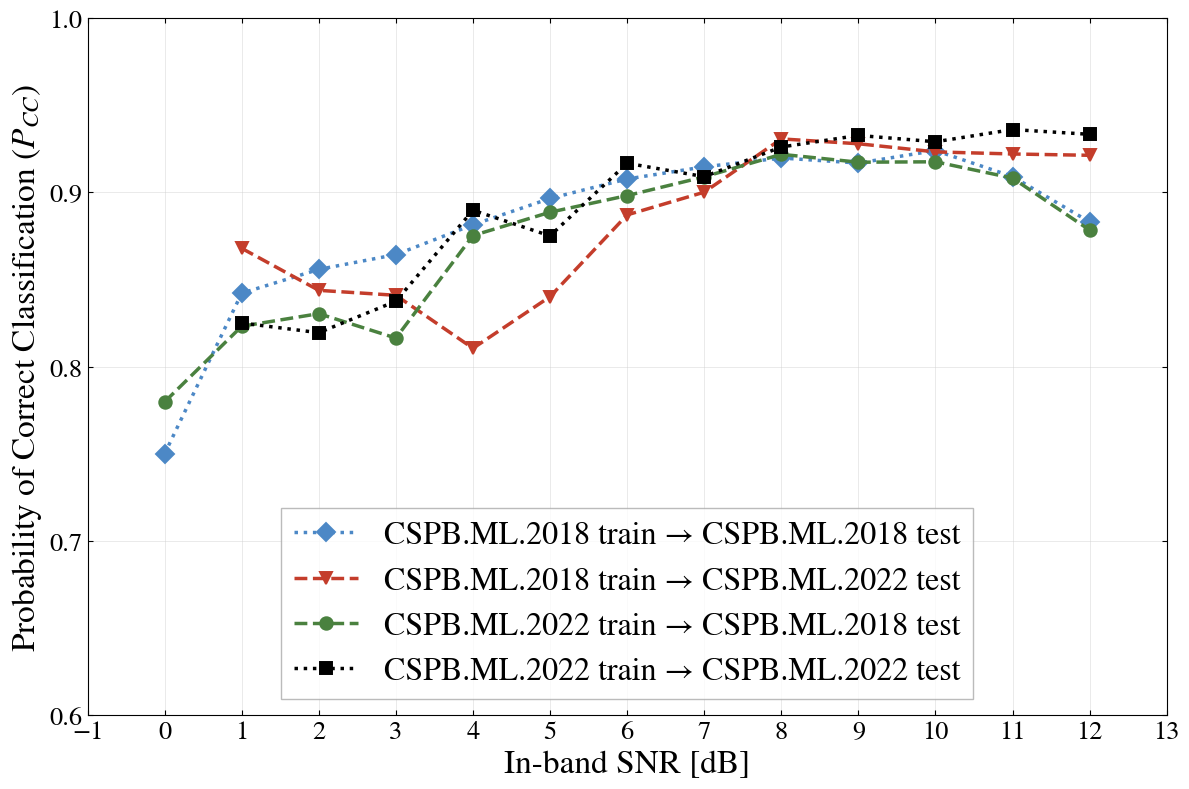

In [12]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})


# ============================================================
# Load per-sample results and calculate accuracy by integer SNR
# ============================================================
files = [
    "snr_acc_samples_2018train20.pt",
    "snr_acc_samples_2022train20.pt",
]

curves = {}

for file in files:
    data = torch.load(
        file,
        map_location="cpu",
        weights_only=False,
    )
    train_mode = data["split_mode"]

    for test_year, result in data["results"].items():
        snr = result["snr"].cpu().numpy()
        true_type = np.asarray(result["true_type"])
        pred_type = np.asarray(result["pred_type"])

        df = pd.DataFrame({
            # Group continuous SNR values into the nearest integer bin.
            "snr": np.rint(snr).astype(int),
            "correct": (true_type == pred_type).astype(float),
        })

        # Keep only the SNR range shown in the figure.
        df = df[df["snr"].between(0, 12)]

        # Calculate the classification accuracy at each SNR.
        curve = (
            df.groupby("snr")["correct"]
            .mean()
            .reindex(range(13))
        )

        curves[f"{train_mode} → {test_year} test"] = curve


# ============================================================
# Plot configuration
# ============================================================
plot_config = {
    "2018train20 → 2018 test": {
        "label": "CSPB.ML.2018 train → CSPB.ML.2018 test",
        "color": "#4C88C6",
        "marker": "D",
        "linestyle": ":",
    },
    "2018train20 → 2022 test": {
        "label": "CSPB.ML.2018 train → CSPB.ML.2022 test",
        "color": "#C43D2B",
        "marker": "v",
        "linestyle": "--",
    },
    "2022train20 → 2018 test": {
        "label": "CSPB.ML.2022 train → CSPB.ML.2018 test",
        "color": "#4A813F",
        "marker": "o",
        "linestyle": "--",
    },
    "2022train20 → 2022 test": {
        "label": "CSPB.ML.2022 train → CSPB.ML.2022 test",
        "color": "#000000",
        "marker": "s",
        "linestyle": ":",
    },
}


# ============================================================
# Draw the four SNR-accuracy curves
# ============================================================
fig, ax = plt.subplots(figsize=(12, 8))

for key, style in plot_config.items():
    if key not in curves:
        print(f"Warning: result not found: {key}")
        continue

    curve = curves[key]

    ax.plot(
        curve.index,
        curve.values,
        label=style["label"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        linewidth=2.5,
        markersize=9,
        markeredgewidth=1.4,
    )


# ============================================================
# Axis and legend formatting
# ============================================================
ax.set_xlabel(
    "In-band SNR [dB]",
    fontsize=24,
)

ax.set_ylabel(
    r"Probability of Correct Classification ($P_{CC}$)",
    fontsize=24,
)

ax.set_xlim(-1, 13)
ax.set_ylim(0.6, 1.0)

ax.set_xticks(np.arange(-1, 14, 1))
ax.set_yticks(np.arange(0.6, 1.01, 0.1))

ax.tick_params(
    axis="both",
    labelsize=19,
    direction="in",
    top=True,
    right=True,
)

ax.grid(
    True,
    color="#D0D0D0",
    linewidth=0.7,
    alpha=0.45,
)

ax.legend(
    loc="lower center",
    fontsize=23,
    frameon=True,
    fancybox=False,
    edgecolor="#AAAAAA",
)

plt.tight_layout()

# Optional:
# plt.savefig(
#     "four_results_snr_accuracy.pdf",
#     dpi=600,
#     bbox_inches="tight",
# )

plt.show()